# Switch routing and expert capacity

An expert may receive more tokens than its buffer can hold. Track the token drops as routing demand grows less even.

The Switch layer chooses one expert per token and scales its output by the selected probability from the full softmax. The auxiliary load loss uses the pre-capacity assignment fraction and the mean softmax probability of each expert.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


import torch
import torch.nn.functional as F
from torch import nn


def seed():
    torch.manual_seed(17)
    torch.set_num_threads(1)


def route(logits, x, scale, capacity_factor):
    p = logits.softmax(-1)
    top = p.argmax(1)
    n, experts = p.shape
    cap = int(np.ceil(capacity_factor * n / experts))
    loads = torch.bincount(top, minlength=experts)
    kept = torch.zeros_like(loads)
    contribution = torch.zeros_like(x)
    for expert in range(experts):
        offered = torch.where(top == expert)[0]
        accepted = offered[:cap]
        kept[expert] = len(accepted)
        contribution[accepted] = p[accepted, expert] * scale[expert] * x[accepted]
    freq = loads.float() / n
    aux = experts * (freq * p.mean(0)).sum()
    return x + contribution, loads, kept, aux, cap

## Measure demand, capacity and loss

Two groups have equal token counts. The skewed group receives an additive logit bias towards the first expert. Overflow tokens follow the identity residual.

In [2]:
seed()
n = 192
scores = torch.randn(n, 4)
values = torch.linspace(0.1, 1, n)
scale = torch.tensor([0.3, 1.2, -0.1, 0.6])
rows = []
cases = {}
for name, bias in [("Balanced", [0.0, 0.0, 0.0, 0.0]), ("Skewed", [2.2, 0.0, 0.0, 0.0])]:
    logits = (scores + torch.tensor(bias)).requires_grad_()
    for factor in (1.0, 1.25, 2.0):
        output, loads, kept, aux, cap = route(logits, values, scale, factor)
        missed = int((loads - kept).sum())
        assert int(kept.sum()) + missed == n and bool((kept <= cap).all())
        assert int(torch.isclose(output, values).sum()) == missed
        rows.append(
            (name, factor, cap, int(loads.max()), missed, missed / n, float(aux.detach()))
        )
        if factor == 1.25:
            cases[name] = (loads.numpy(), kept.numpy())
    aux.backward()
    assert logits.grad is not None and torch.isfinite(logits.grad).all()
report(
    [
        "Batch",
        "Capacity factor",
        "Slots per expert",
        "Peak demand",
        "Dropped tokens",
        "Drop fraction",
        "Auxiliary loss",
    ],
    rows,
)

,Batch,Capacity factor,Slots per expert,Peak demand,Dropped tokens,Drop fraction,Auxiliary loss
0,Balanced,1.00,48,51,5,0.02604,1.00155
1,Balanced,1.25,60,51,0,0.00000,1.00155
2,Balanced,2.00,96,51,0,0.00000,1.00155
3,Skewed,1.00,48,165,117,0.60938,2.35297
4,Skewed,1.25,60,165,105,0.54688,2.35297
5,Skewed,2.00,96,165,69,0.35938,2.35297


## Compare demand with admitted tokens

At capacity factor 1.25, compare demand and completed expert calls. Token order resolves overflow here.

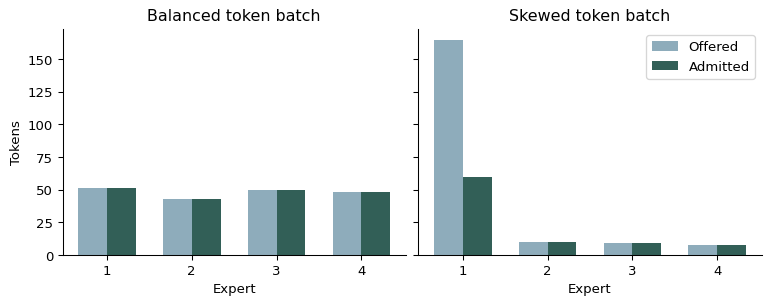

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.1), layout="constrained", sharey=True)
for ax, (name, (offer, keep)) in zip(axes, cases.items()):
    index = np.arange(4)
    ax.bar(index - 0.17, offer, 0.34, label="Offered", color="#8eacbb")
    ax.bar(index + 0.17, keep, 0.34, label="Admitted", color="#325f57")
    ax.set(xticks=index, xticklabels=index + 1, xlabel="Expert", title=name + " token batch")
axes[0].set_ylabel("Tokens")
axes[1].legend()
plt.show()

## Interpreting the result

With 60 slots per expert, the balanced batch admitted all 192 tokens. In the skewed batch, 165 tokens selected one expert and 105 missed an expert update. Each of those tokens still followed the residual path.

The auxiliary term diagnoses the distribution of demand before clipping. Increasing capacity can lower the drop fraction even though that term is unchanged for the same logits.

## Exercise

Shuffle the skewed batch before dispatch and undo the shuffle afterwards. Check which individual tokens now receive an expert update.

## References

[Fedus, Zoph and Shazeer (2022), Switch Transformers](https://arxiv.org/abs/2101.03961)

[Shazeer et al. (2017), Outrageously Large Neural Networks](https://arxiv.org/abs/1701.06538)